<a href="https://colab.research.google.com/github/zogydinesh/ITA-0616/blob/main/program20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Rows: 200  Columns: 4
      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3   12.0
3  151.5   41.3       58.5   16.5
4  180.8   10.8       58.4   17.9 

Correlation of each ad channel with Sales:
TV           0.901
Radio        0.350
Newspaper    0.158 

Train size: 160  Test size: 40 

Model 1: Sales = 4.744 + 0.0536 x TV + 0.1089 x Radio + -0.0020 x Newspaper
  Test  MAE = 1.319   RMSE = 1.876   R2 = 0.8808
  Train R2  = 0.9079

Model 2: Model 1 + (TV x Radio) column
  Test  MAE = 1.282   RMSE = 1.738   R2 = 0.8977

Actual vs Predicted sales (first 6 test rows, Model 2):
  Actual =  27.0   Predicted =  26.1
  Actual =  10.8   Predicted =  10.2
  Actual =  17.2   Predicted =  15.8
  Actual =  26.2   Predicted =  25.8
  Actual =  14.0   Predicted =  13.3
  Actual =  20.2   Predicted =  22.1

Future sales prediction for planned ad budgets (thousand $ -> thousand units):
         Plan  TV  Radio  Newspaper  Predic

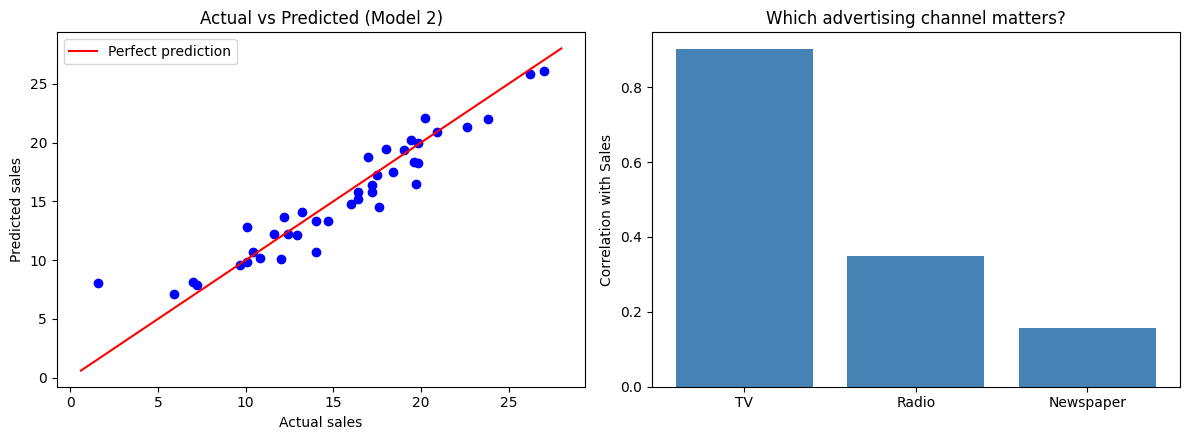

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Dataset: Advertising and Sales (program20.csv, used as it is)
# TV, Radio, Newspaper = advertising budget in thousands of dollars, Sales = units sold (thousands)

# ---- 1. Load CSV ----
df = pd.read_csv('program20.csv')
print("Rows:", len(df), " Columns:", df.shape[1])
print(df.head(), "\n")
print("Correlation of each ad channel with Sales:")
print(df.corr()['Sales'].drop('Sales').round(3).to_string(), "\n")

# ---- 2. Train / test split (80% / 20%) ----
np.random.seed(42)
idx = np.random.permutation(len(df))
split = int(0.8 * len(df))
train, test = df.iloc[idx[:split]], df.iloc[idx[split:]]
ytr, yte = train['Sales'].values, test['Sales'].values
print("Train size:", len(train), " Test size:", len(test), "\n")

# ---- 3. Multiple Linear Regression (least squares) ----
def fit(X, y):
    A = np.column_stack([np.ones(len(X)), X])             # column of 1s = intercept
    return np.linalg.lstsq(A, y, rcond=None)[0]

def predict(w, X):
    return np.column_stack([np.ones(len(X)), X]) @ w

def metrics(actual, predicted):
    mae = np.mean(np.abs(actual - predicted))
    rmse = np.sqrt(np.mean((actual - predicted) ** 2))
    r2 = 1 - np.sum((actual - predicted) ** 2) / np.sum((actual - actual.mean()) ** 2)
    return mae, rmse, r2

features = ['TV', 'Radio', 'Newspaper']
w = fit(train[features].values, ytr)
print("Model 1: Sales = {:.3f} + {:.4f} x TV + {:.4f} x Radio + {:.4f} x Newspaper".format(*w))
pred1 = predict(w, test[features].values)
mae, rmse, r2 = metrics(yte, pred1)
print(f"  Test  MAE = {mae:.3f}   RMSE = {rmse:.3f}   R2 = {r2:.4f}")
print(f"  Train R2  = {metrics(ytr, predict(w, train[features].values))[2]:.4f}\n")

# ---- 4. Model 2: add a TV x Radio column (TV and Radio help each other) ----
def with_interaction(d):
    return np.column_stack([d['TV'], d['Radio'], d['Newspaper'], d['TV'] * d['Radio']])

w2 = fit(with_interaction(train), ytr)
pred2 = predict(w2, with_interaction(test))
mae2, rmse2, r22 = metrics(yte, pred2)
print("Model 2: Model 1 + (TV x Radio) column")
print(f"  Test  MAE = {mae2:.3f}   RMSE = {rmse2:.3f}   R2 = {r22:.4f}\n")

# ---- 5. Actual vs predicted ----
print("Actual vs Predicted sales (first 6 test rows, Model 2):")
for a, p in zip(yte[:6], pred2[:6]):
    print(f"  Actual = {a:5.1f}   Predicted = {p:5.1f}")

# ---- 6. Predict FUTURE sales for planned advertising budgets ----
plans = pd.DataFrame({
    'Plan': ['Low budget', 'Medium budget', 'High budget', 'Radio-heavy'],
    'TV': [50, 150, 250, 100],
    'Radio': [10, 25, 45, 45],
    'Newspaper': [10, 30, 60, 10]
})
plans['Predicted Sales'] = predict(w2, with_interaction(plans)).round(2)
print("\nFuture sales prediction for planned ad budgets (thousand $ -> thousand units):")
print(plans.to_string(index=False))

# ---- 7. Plots ----
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(yte, pred2, color='blue')
lim = [yte.min() - 1, yte.max() + 1]
ax[0].plot(lim, lim, color='red', label='Perfect prediction')
ax[0].set_xlabel('Actual sales')
ax[0].set_ylabel('Predicted sales')
ax[0].set_title('Actual vs Predicted (Model 2)')
ax[0].legend()

ax[1].bar(['TV', 'Radio', 'Newspaper'], df.corr()['Sales'].drop('Sales').values, color='steelblue')
ax[1].set_ylabel('Correlation with Sales')
ax[1].set_title('Which advertising channel matters?')
plt.tight_layout()
plt.show()